# Mobile Game Player Spending Segmentation
## 03 — Exploratory Data Analysis and Feature Engineering

This notebook reads `mobile_game_players_cleaned.csv` from Stage 2 and explores player spending segments, purchase behavior, ad views, activity, genres, countries, devices, acquisition/payment channels, purchase timing, and date coverage. It creates activity-rate features for modelling and flags timing-related target leakage.

**Important:** the expanded rows and generated behavior are synthetic training data. Findings are descriptive patterns in this dataset, not verified NovaPlay customer behavior or causal effects.



## 1. Read the cleaned dataset

This notebook uses the known filename directly; it does not ask you to upload the file. Run the cleaning notebook first in the same Colab session so `mobile_game_players_cleaned.csv` is available in the current folder. The EDA only makes a working copy and does not clean the dataset again.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

FILE_NAME = 'mobile_game_players_cleaned.csv'
if not Path(FILE_NAME).exists():
    raise FileNotFoundError(
        f'{FILE_NAME} was not found. Place the agreed cleaned CSV beside this notebook; this EDA does not rerun cleaning.'
    )

df = pd.read_csv(FILE_NAME)
for date_column in ['InstallDate', 'LastPurchaseDate']:
    if date_column in df.columns:
        df[date_column] = pd.to_datetime(df[date_column], errors='coerce')
install_coverage = df['InstallDate'].notna().mean() if 'InstallDate' in df.columns else 0
print('InstallDate parse coverage:', f'{install_coverage:.2%}')
if install_coverage < 0.99:
    raise ValueError('InstallDate coverage is below 99%; stop before date EDA and inspect the cleaning notebook output.')
segment_order = ['Minnow', 'Dolphin', 'Whale']
segment_colors = {'Minnow': '#6baed6', 'Dolphin': '#fd8d3c', 'Whale': '#756bb1'}
sns.set_theme(style='whitegrid')

print('File:', FILE_NAME)
print('Rows x columns:', df.shape)
if len(df) < 200_000:
    raise ValueError(f'This file has only {len(df):,} rows; use the agreed cleaned dataset with at least 200,000 rows.')
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.head())


InstallDate parse coverage: 100.00%
File: mobile_game_players_cleaned.csv
Rows x columns: (247500, 25)
Duplicate rows: 0


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate,InAppPurchaseAmountWasMissing,FirstPurchaseDaysAfterInstallWasMissing
0,PLAYER005364744676376,49.0,Male,Norway,Android,Battle Royale,9.0,12.83,Minnow,11.40,...,5.0,4.0,7.0,1.0,No,No,0.0,0.728,0,0
1,PLAYER447523025485744,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,3.0,4.0,6.0,3.0,No,Yes,0.0,0.183,0,0
2,PLAYER445146626174337,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,5.0,5.0,4.0,5.0,No,No,2.0,0.384,0,0
3,PLAYER673007615056419,31.0,Male,Mexico,Android,Racing,12.0,19.92,Minnow,13.49,...,8.0,8.0,8.0,1.0,Yes,No,0.0,0.265,0,0
4,PLAYER316428408427736,37.0,Female,India,Android,Battle Royale,10.0,15.23,Minnow,10.86,...,4.0,4.0,5.0,3.0,No,No,0.0,0.285,0,0


## 2. Analysis setup and data coverage

Convert only columns needed for calculations and plots; this is analysis preparation, not another cleaning pass. Dates may be missing because of the source/simulation process. Review missing counts before interpreting date charts.

In [2]:
numeric_columns = [
    'Age', 'SessionCount', 'AverageSessionLength', 'InAppPurchaseAmount',
    'FirstPurchaseDaysAfterInstall', 'ActiveDays30d', 'PlayerLevel30d',
    'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d', 'WinRate'
]
for column in numeric_columns:
    if column in df.columns:
        text = df[column].astype('string').str.replace('$', '', regex=False).str.strip()
        df[column] = pd.to_numeric(text, errors='coerce')

def parse_date_column(series):
    text = series.astype('string').str.strip()
    result = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    formats = [('%Y-%m-%d', r'^\d{4}-\d{2}-\d{2}(?:[ T].*)?$'),
               ('%m/%d/%Y', r'^\d{1,2}/\d{1,2}/\d{4}$'),
               ('%d-%m-%Y', r'^\d{1,2}-\d{1,2}-\d{4}$')]
    for date_format, pattern in formats:
        mask = text.str.match(pattern, na=False)
        result.loc[mask] = pd.to_datetime(text.loc[mask], errors='coerce') if date_format == '%Y-%m-%d' else pd.to_datetime(text.loc[mask], format=date_format, errors='coerce')
    return result

for column in ['InstallDate', 'LastPurchaseDate']:
    if column in df.columns:
        df[column] = parse_date_column(df[column])

# Final canonical alias: one source row had the truncated device label 'Androi'.
if 'Device' in df.columns:
    df['Device'] = df['Device'].replace({'Androi': 'Android', 'androi': 'Android'})

print('Duplicate rows:', int(df.duplicated().sum()))
print('Missing value counts in key analysis columns:')
key_columns = [c for c in ['InstallDate','LastPurchaseDate','FirstPurchaseDaysAfterInstall','InAppPurchaseAmount','GameGenre','Country','Device'] if c in df.columns]
display(df[key_columns].isna().sum().to_frame('missing_rows'))


Duplicate rows: 0
Missing value counts in key analysis columns:


,missing_rows
InstallDate,1
LastPurchaseDate,11157
FirstPurchaseDaysAfterInstall,0
InAppPurchaseAmount,0
GameGenre,0
Country,0
Device,0


## Missing values — what is missing, and why?

This chart is a file-quality audit, not a cleaning step. The cleaned CSV created by Stage 2 is the fixed input for this analysis. An unavailable event date does **not** mean a player row was removed. `InstallDate` should have at least 99% parseable coverage after cleaning; the input cell stops the EDA if that check fails. No rows are dropped in this EDA.

The `InAppPurchaseAmountWasMissing` and `FirstPurchaseDaysAfterInstallWasMissing` fields are complete binary indicators with values `0` or `1`; they are not null-valued fields. The EDA uses them to distinguish supplied values from median-filled values where that distinction matters.


,missing_rows,missing_percent
LastPurchaseDate,11157,4.51
InstallDate,1,0.00
FirstPurchaseDaysAfterInstall,0,0.00
InAppPurchaseAmount,0,0.00
GameGenre,0,0.00
Country,0,0.00
Device,0,0.00


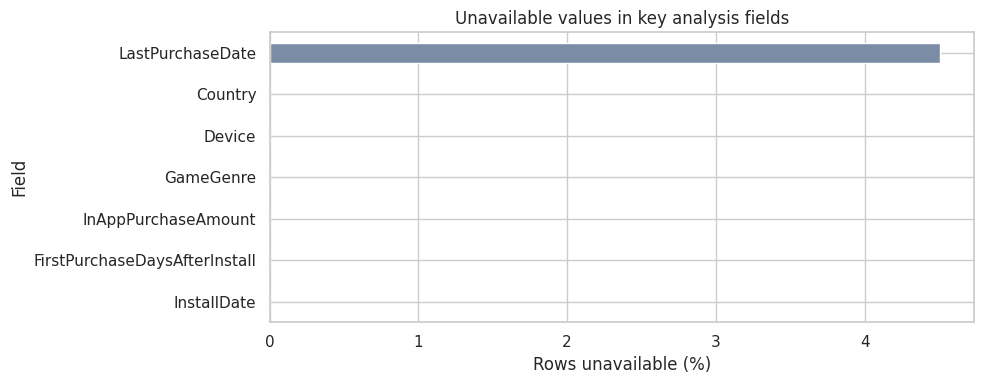

InstallDate unavailable after cleaning: 0.000%. No rows are dropped in EDA.


In [3]:
audit_columns = [c for c in [
    'InstallDate','LastPurchaseDate','FirstPurchaseDaysAfterInstall',
    'InAppPurchaseAmount','GameGenre','Country','Device'
] if c in df.columns]
missing_audit = pd.DataFrame({
    'missing_rows': df[audit_columns].isna().sum(),
    'missing_percent': (df[audit_columns].isna().mean() * 100).round(2)
}).sort_values('missing_percent', ascending=False)
display(missing_audit)

fig, ax = plt.subplots(figsize=(10,4))
missing_audit['missing_percent'].sort_values().plot.barh(ax=ax, color='#7b8da6')
ax.set_title('Unavailable values in key analysis fields')
ax.set_xlabel('Rows unavailable (%)'); ax.set_ylabel('Field')
plt.tight_layout(); plt.show()

if 'InstallDate' in missing_audit.index:
    rate = missing_audit.loc['InstallDate','missing_percent']
    if rate > 10:
        valid_dates = int(df['InstallDate'].notna().sum())
        print(f'InstallDate unavailable after cleaning: {rate:.3f}% ({valid_dates:,} parseable dates). This should be limited to deliberately invalid date records; it is not a player-row removal.')
    else:
        print(f'InstallDate unavailable after cleaning: {rate:.3f}%. No rows are dropped in EDA.')


## 3. Dataset size, date range, and distributions

Report calendar ranges separately: install dates and last-purchase dates describe different events. `FirstPurchaseDaysAfterInstall` is an elapsed number of days, not a calendar date. Also view the distributions of age, ads, active days, and purchase count to understand typical values and skew.

In [4]:
print(f'Rows: {len(df):,}; columns: {df.shape[1]}')
for column in ['InstallDate', 'LastPurchaseDate']:
    if column in df.columns:
        dates = df[column].dropna()
        if len(dates):
            print(f'{column}: {dates.min().date()} through {dates.max().date()} ({len(dates):,} valid rows)')
        else:
            print(f'{column}: no valid dates')
print('FirstPurchaseDaysAfterInstall is elapsed days, not a calendar date.')


Rows: 247,500; columns: 25
InstallDate: 2022-07-16 through 2025-08-12 (247,499 valid rows)
LastPurchaseDate: 2025-01-01 through 2025-08-13 (236,343 valid rows)
FirstPurchaseDaysAfterInstall is elapsed days, not a calendar date.


### Age distribution
**What to look for:** the median and spread describe the player ages in this dataset. A histogram shows concentration and skew; it does not establish which age group is more valuable until compared with the target.


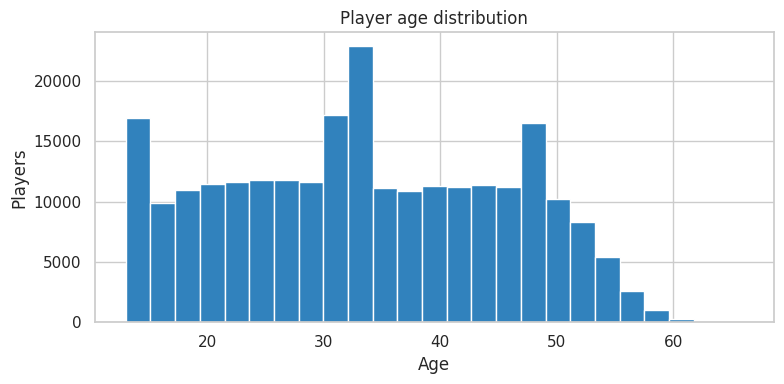

Age median: 33.0 | IQR: 19.0


In [5]:
plt.figure(figsize=(8,4))
plt.hist(df['Age'].dropna(), bins=25, color='#3182bd', edgecolor='white')
plt.title('Player age distribution')
plt.xlabel('Age'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Age median:', round(df['Age'].median(),1), '| IQR:', round(df['Age'].quantile(.75)-df['Age'].quantile(.25),1))


### Ad views in the first 30 days
**What it means:** this shows how many ads players watched. By itself it does not show whether ads are related to purchasing; compare it with purchase count in Section 7.


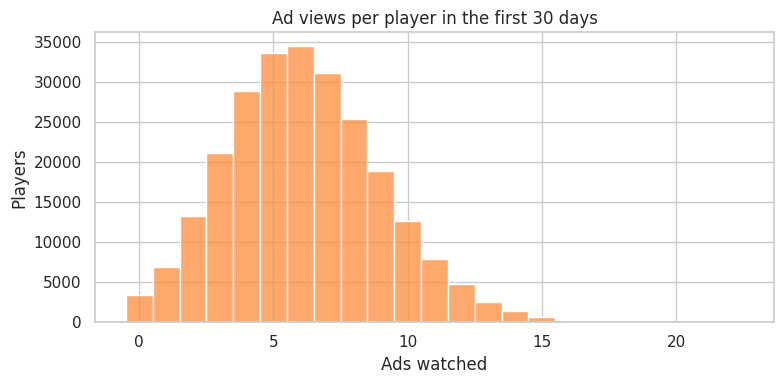

Median ad views: 6.0 | 90th percentile: 10.0


In [6]:
plt.figure(figsize=(8,4))
sns.histplot(df['AdsWatched30d'].dropna(), discrete=True, color='#fd8d3c')
plt.title('Ad views per player in the first 30 days')
plt.xlabel('Ads watched'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Median ad views:', df['AdsWatched30d'].median(), '| 90th percentile:', df['AdsWatched30d'].quantile(.90))


### Active days in the first 30 days
**What it means:** this describes how many days players returned during the observation window. It is an exposure measure, so count-based behavior should also be compared per active day.


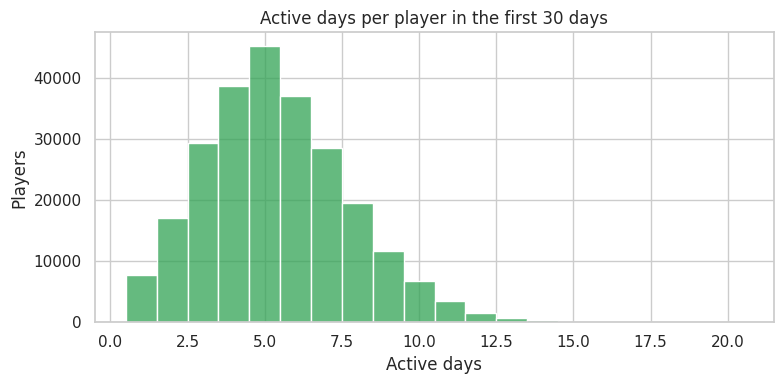

Median active days: 5.0 | 90th percentile: 8.0


In [7]:
plt.figure(figsize=(8,4))
sns.histplot(df['ActiveDays30d'].dropna(), discrete=True, color='#31a354')
plt.title('Active days per player in the first 30 days')
plt.xlabel('Active days'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Median active days:', df['ActiveDays30d'].median(), '| 90th percentile:', df['ActiveDays30d'].quantile(.90))


### Purchase count in the first 30 days
**What it means:** unlike positive IAP amount, `PurchaseCount30d > 0` is the more direct available indicator of at least one purchase in this dataset. Check its zero share and distribution before comparing segments.


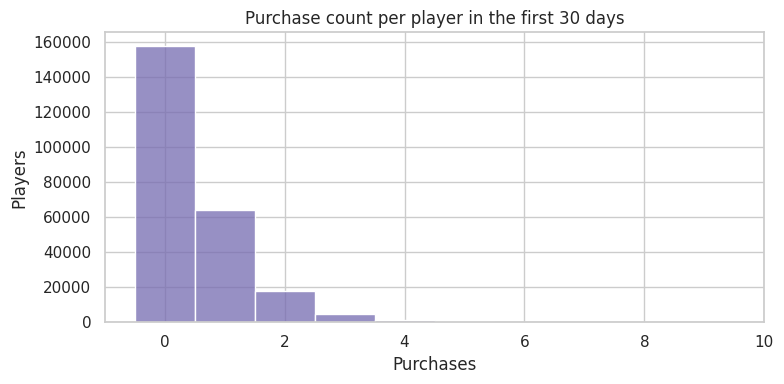

Players with zero recorded purchases: 63.8%
Median purchase count: 0.0


In [8]:
plt.figure(figsize=(8,4))
sns.histplot(df['PurchaseCount30d'].dropna(), discrete=True, color='#756bb1')
plt.title('Purchase count per player in the first 30 days')
plt.xlabel('Purchases'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Players with zero recorded purchases:', f"{(df['PurchaseCount30d'].fillna(0)==0).mean()*100:.1f}%")
print('Median purchase count:', df['PurchaseCount30d'].median())


**Why this matters:** skewed variables and rare extreme values affect which summary statistics are useful. Report medians and ranges as well as means when distributions are skewed. Date coverage also helps identify whether temporal comparisons are meaningful; simulated dates should not be described as NovaPlay's real operating history.

## 4. What does the spending-segment mix look like?

Show both counts and proportions. A large Minnow group can make overall accuracy misleading if the modeling task is to identify Dolphins or Whales.

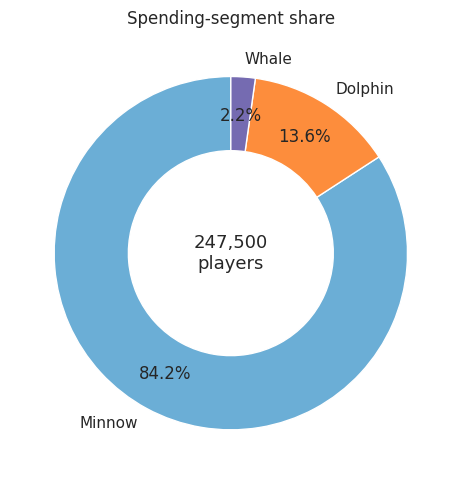

,players,share_percent
SpendingSegment,,
Minnow,208328,84.17
Dolphin,33670,13.60
Whale,5502,2.22


In [9]:
counts = df['SpendingSegment'].value_counts().reindex(segment_order, fill_value=0)
shares = (counts / len(df) * 100).round(2)
fig, ax = plt.subplots(figsize=(7,5))
ax.pie(counts, labels=segment_order, autopct='%1.1f%%', startangle=90,
       colors=[segment_colors[s] for s in segment_order], pctdistance=.78,
       wedgeprops={'width':.42, 'edgecolor':'white'})
ax.text(0,0,f'{len(df):,}\nplayers',ha='center',va='center',fontsize=13)
ax.set_title('Spending-segment share')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'players':counts, 'share_percent':shares}))


**Business decision:** if Whale is rare, use per-class precision, recall, F1, and a confusion matrix in modeling. The cost of missing a valuable player and the cost of sending an unnecessary offer may differ.

## 5. Which game genres show stronger purchase behavior?

Compare purchase conversion based on `PurchaseCount30d > 0`, average purchase count, and IAP amount among records where the amount was originally observed. The interactive bubble plot uses x=conversion, y=IAP value used in summary, bubble size=players, and color=average purchase count. Hover over a genre for details. The heatmap shows which spending tiers make up each genre.


,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
GameGenre,,,,,,,
Battle Royale,15431,5662,2239400.77,157.14,12.07,0.53,36.69
Racing,15540,5915,2254461.32,156.38,12.58,0.54,38.06
Strategy,16174,5993,2161014.52,143.26,11.02,0.54,37.05
Fighting,14781,5645,1903264.29,138.54,12.38,0.55,38.19
MOBA,14893,5446,1926150.63,138.42,11.81,0.51,36.57
Unknown,4923,1796,519032.45,114.4,13.58,0.51,36.48
Adventure,13846,5397,1237102.17,96.2,11.91,0.55,38.98
MMORPG,16024,5724,1371521.92,92.35,12.47,0.49,35.72
Role Playing,15927,5756,1348122.59,91.37,11.08,0.5,36.14


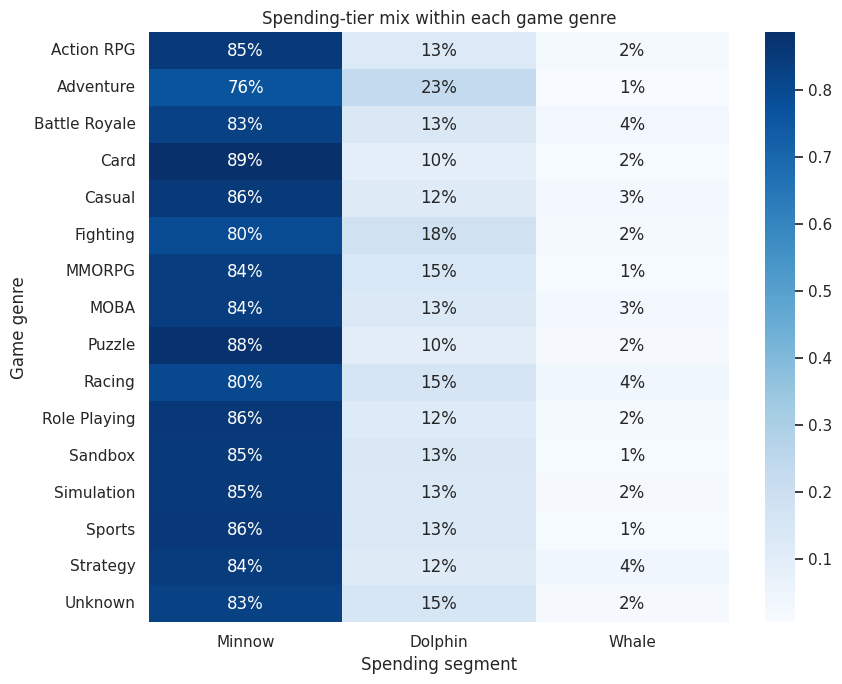

In [10]:
# Use actual purchase count (>0) as the purchase indicator. A small positive IAP can exist in Minnow records, so amount > 0 is not a reliable conversion definition.
df['HasPurchase30d'] = df['PurchaseCount30d'].fillna(0) > 0
if 'InAppPurchaseAmountWasMissing' in df.columns:
    df['AmountKnown'] = df['InAppPurchaseAmountWasMissing'] == 0
else:
    df['AmountKnown'] = df['InAppPurchaseAmount'].notna()
df['IAPForSummary'] = df['InAppPurchaseAmount'].where(df['AmountKnown'])
if 'InAppPurchaseAmountWasMissing' not in df.columns:
    print('Amount summaries use the IAP values stored in the fixed CSV; some may have been imputed earlier, so do not interpret these figures as verified observed revenue.')

def summarize_group(column):
    summary = df.groupby(column, dropna=False).agg(
        players=(column, 'size'),
        purchasers=('HasPurchase30d', 'sum'),
        total_iap_used_for_summary=('IAPForSummary', 'sum'),
        mean_iap_used_for_summary=('IAPForSummary', 'mean'),
        median_iap_used_for_summary=('IAPForSummary', 'median'),
        mean_purchase_count=('PurchaseCount30d', 'mean')
    )
    summary['purchase_rate_percent'] = 100 * summary['purchasers'] / summary['players'].replace(0,np.nan)
    return summary.sort_values('mean_iap_used_for_summary', ascending=False)

genre_summary = summarize_group('GameGenre')
display(genre_summary.round(2))
minimum_players = 100
genre_plot = genre_summary[genre_summary['players'] >= minimum_players].copy()
genre_plot['Genre'] = genre_plot.index.astype(str)

# Interactive bubble chart: hover for sample size, purchase rate, purchase frequency and IAP value used in summary.
fig = px.scatter(genre_plot, x='purchase_rate_percent', y='mean_iap_used_for_summary',
                 size='players', color='mean_purchase_count', hover_name='Genre',
                 hover_data={'players':':,','purchase_rate_percent':':.1f',
                             'mean_purchase_count':':.2f','mean_iap_used_for_summary':':.2f'},
                 color_continuous_scale='Viridis', size_max=55,
                 title='Genre purchase profile: conversion, IAP values used in summary, and group size')
fig.update_layout(xaxis_title='Players with at least one 30-day purchase (%)',
                  yaxis_title='Mean IAP value used in summary (USD)')
fig.show()

# Heatmap shows which spending tiers make up each genre.
segment_by_genre = pd.crosstab(df['GameGenre'], df['SpendingSegment'], normalize='index').reindex(columns=segment_order, fill_value=0)
plt.figure(figsize=(9,7))
sns.heatmap(segment_by_genre, annot=True, fmt='.0%', cmap='Blues')
plt.title('Spending-tier mix within each game genre')
plt.xlabel('Spending segment'); plt.ylabel('Game genre')
plt.tight_layout(); plt.show()


**Business meaning:** the bubble chart separates three useful questions: how many players make a purchase, the mean IAP value included in the summary (which may include imputed values), and how large the genre sample is. The heatmap shows whether a genre's profile comes from Minnows, Dolphins, or Whales. These are descriptive associations in simulated data, not evidence that genre causes spending.


## 6. Are ad views associated with purchase behavior?

Use complementary views: a scatter plot for individual-level pattern, ad-view bins for purchase rate, and summaries by segment. Binning helps reveal a trend when many points overlap. Purchase conversion is defined as `PurchaseCount30d > 0`, not a positive IAP amount. This avoids treating imputed amounts as proof of a purchase.

,players,purchase_rate,mean_purchase_count,median_active_days,purchase_rate_percent
AdViewBand,,,,,
0-1,10243,0.63,1.25,5.0,62.76
2-3,34420,0.43,0.66,5.0,42.68
4-5,62497,0.35,0.48,5.0,35.1
6-8,91062,0.33,0.42,5.0,32.88
9-12,44239,0.33,0.42,6.0,33.5
13+,5039,0.36,0.46,7.0,36.26


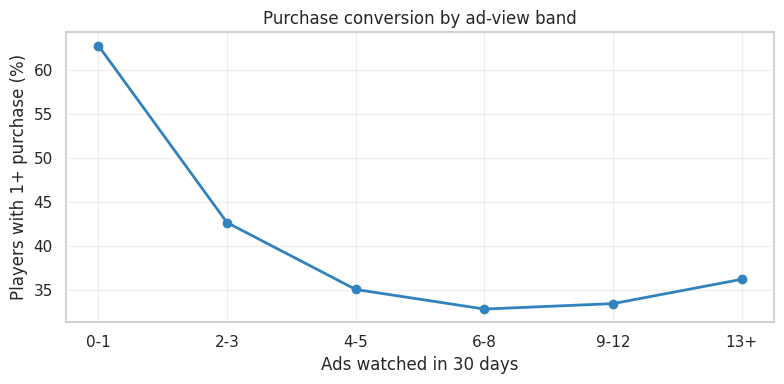

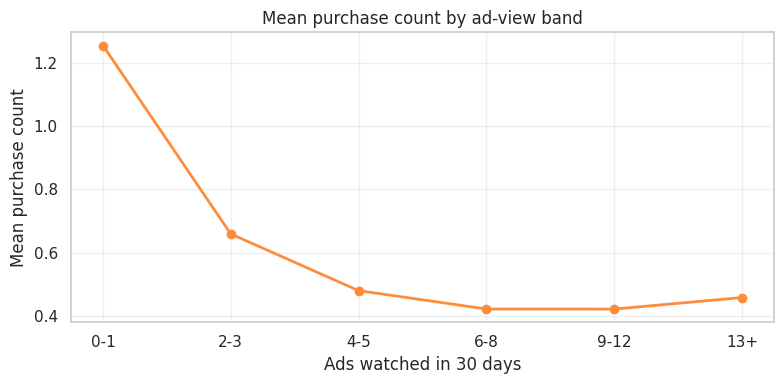

Spearman correlation, AdsWatched30d vs PurchaseCount30d: -0.105


In [11]:
# Interactive scatter: each dot is a player; hover reveals context.
scatter_columns = ['AdsWatched30d','PurchaseCount30d','SpendingSegment','GameGenre','Country','ActiveDays30d']
scatter_data = df[scatter_columns].dropna(subset=['AdsWatched30d','PurchaseCount30d']).copy()
if len(scatter_data) > 20000:
    scatter_data = scatter_data.sample(20000, random_state=42)
fig = px.scatter(scatter_data, x='AdsWatched30d', y='PurchaseCount30d',
                 color='SpendingSegment', color_discrete_map=segment_colors,
                 hover_data=['GameGenre','Country','ActiveDays30d'], opacity=.45,
                 title='Ad views vs purchase count (hover for player context)')
fig.update_layout(xaxis_title='Ads watched in first 30 days', yaxis_title='Purchase count in first 30 days')
fig.show()

# Purchase behavior across ad-view bands; conversion uses purchase count, not amount > 0.
ad_bins = [-1, 1, 3, 5, 8, 12, np.inf]
ad_labels = ['0-1','2-3','4-5','6-8','9-12','13+']
df['AdViewBand'] = pd.cut(df['AdsWatched30d'], bins=ad_bins, labels=ad_labels)
ad_summary = df.groupby('AdViewBand', observed=False).agg(
    players=('AdViewBand','size'), purchase_rate=('HasPurchase30d','mean'),
    mean_purchase_count=('PurchaseCount30d','mean'), median_active_days=('ActiveDays30d','median')
)
ad_summary['purchase_rate_percent'] = 100 * ad_summary['purchase_rate']
display(ad_summary.round(2))
fig, ax = plt.subplots(figsize=(8,4))
ad_summary['purchase_rate_percent'].plot(marker='o', linewidth=2, color='#3182bd', ax=ax)
ax.set_title('Purchase conversion by ad-view band')
ax.set_xlabel('Ads watched in 30 days'); ax.set_ylabel('Players with 1+ purchase (%)')
ax.grid(True,alpha=.3); plt.tight_layout(); plt.show()

# Binned trend provides an uncluttered companion to the interactive scatter.
fig, ax = plt.subplots(figsize=(8,4))
ad_summary['mean_purchase_count'].plot(marker='o', linewidth=2, color='#fd8d3c', ax=ax)
ax.set_title('Mean purchase count by ad-view band')
ax.set_xlabel('Ads watched in 30 days'); ax.set_ylabel('Mean purchase count')
ax.grid(True,alpha=.3); plt.tight_layout(); plt.show()
print('Spearman correlation, AdsWatched30d vs PurchaseCount30d:', round(df[['AdsWatched30d','PurchaseCount30d']].corr(method='spearman').iloc[0,1],3))


**Interpretation:** look for a consistent trend across the scatter, binned purchase rates, and correlation. A relationship is not proof that ads cause purchases. These fields were synthetically generated, so describe the result as a training-data pattern and do not make ad-monetization claims from it.

## 7. Does activity relate to spending or purchase frequency?

Compare active days and session count with spending tier and purchase count. Use scatter/hexbin-style density and boxplots because large datasets create overplotting. Purchase count is appropriate for descriptive analysis; whether it is valid as a model input depends on the prediction time.

/tmp/ipykernel_798/1121245333.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




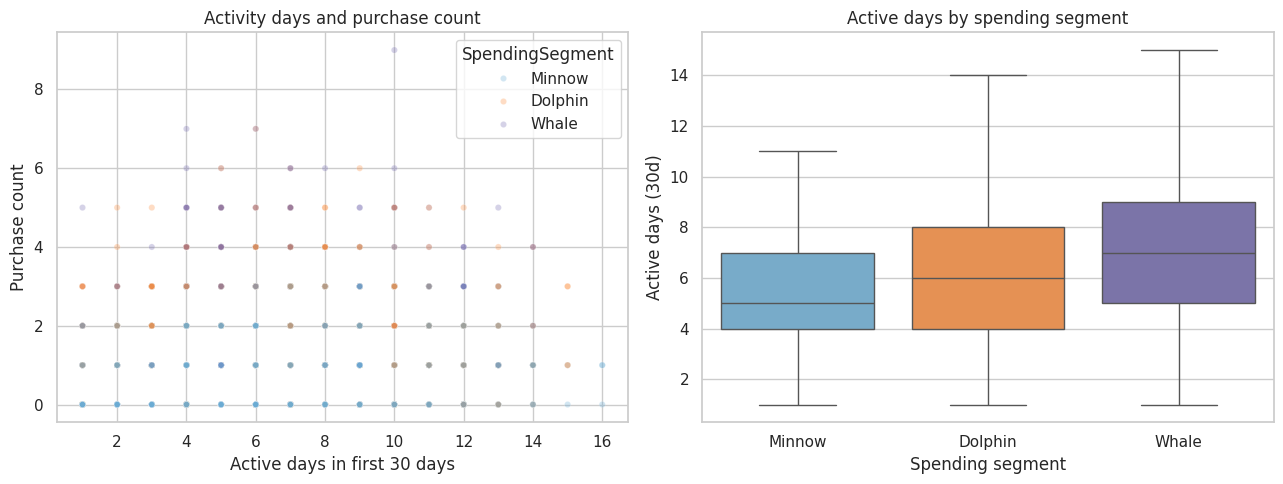

Spearman correlations:


,ActiveDays30d,SessionCount,AdsWatched30d,PurchaseCount30d,InAppPurchaseAmount
ActiveDays30d,1.000,0.143,0.209,0.201,0.080
SessionCount,0.143,1.000,0.032,0.032,0.001
AdsWatched30d,0.209,0.032,1.000,-0.105,-0.236
PurchaseCount30d,0.201,0.032,-0.105,1.000,0.210
InAppPurchaseAmount,0.080,0.001,-0.236,0.210,1.000


In [12]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
activity_sample = df[['ActiveDays30d','PurchaseCount30d','SpendingSegment']].dropna()
if len(activity_sample) > 15000:
    activity_sample = activity_sample.sample(15000, random_state=7)
sns.scatterplot(data=activity_sample, x='ActiveDays30d', y='PurchaseCount30d', hue='SpendingSegment',
                hue_order=segment_order, palette=segment_colors, alpha=.3, s=20, ax=axes[0])
axes[0].set_title('Activity days and purchase count')
axes[0].set_xlabel('Active days in first 30 days'); axes[0].set_ylabel('Purchase count')
sns.boxplot(data=df, x='SpendingSegment', y='ActiveDays30d', order=segment_order,
            palette=segment_colors, showfliers=False, ax=axes[1])
axes[1].set_title('Active days by spending segment')
axes[1].set_xlabel('Spending segment'); axes[1].set_ylabel('Active days (30d)')
plt.tight_layout(); plt.show()

print('Spearman correlations:')
display(df[['ActiveDays30d','SessionCount','AdsWatched30d','PurchaseCount30d','InAppPurchaseAmount']].corr(method='spearman').round(3))


**Business interpretation:** more active players may have more opportunities to see offers and make purchases. Compare rates per active day in the feature-engineering section to reduce the effect of exposure time. The generated data does not prove that increasing activity will increase revenue.

## 8. When does the first purchase happen after installation?

Analyze elapsed days and compare by spending tier. The cleaning notebook preserves `FirstPurchaseDaysAfterInstallWasMissing` as a numeric 0/1 indicator. This chart uses values where the indicator is 0, so median-filled values do not distort observed-delay summaries.

Rows used for observed first-purchase-delay analysis: 208006


/tmp/ipykernel_798/2211792524.py:13: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




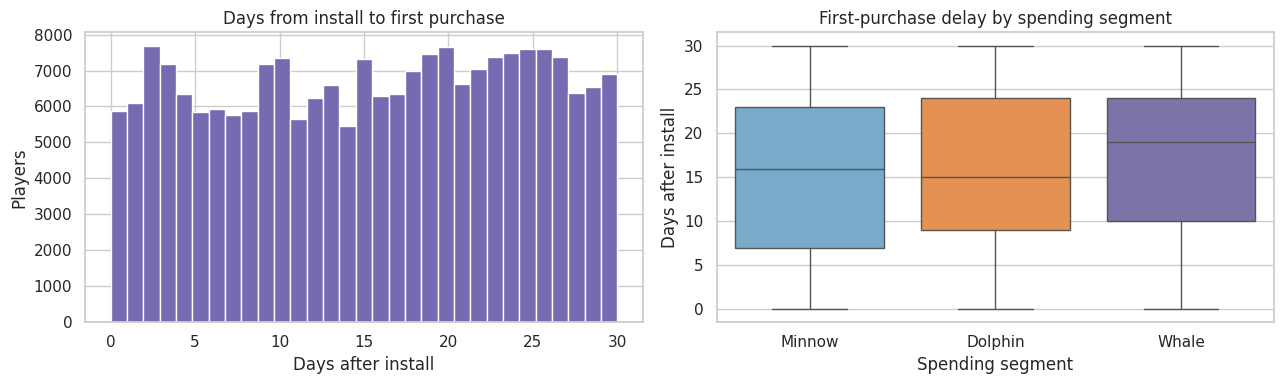

,count,median,mean,min,max
SpendingSegment,,,,,
Minnow,175273,16.0,15.28,0.0,30.0
Dolphin,28208,15.0,15.87,0.0,30.0
Whale,4525,19.0,16.58,0.0,30.0


In [13]:
if 'FirstPurchaseDaysAfterInstallWasMissing' in df.columns:
    delay_data = df.loc[df['FirstPurchaseDaysAfterInstallWasMissing'].eq(0)].copy()
else:
    delay_data = df.dropna(subset=['FirstPurchaseDaysAfterInstall']).copy()
    print('No 0/1 delay indicator is present; values are analyzed as stored in the cleaned CSV.')
delay = delay_data['FirstPurchaseDaysAfterInstall'].dropna()
print('Rows used for observed first-purchase-delay analysis:', len(delay))
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].hist(delay, bins=31, color='#756bb1', edgecolor='white')
axes[0].set_title('Days from install to first purchase')
axes[0].set_xlabel('Days after install'); axes[0].set_ylabel('Players')
delay_by_segment = delay_data
sns.boxplot(data=delay_by_segment, x='SpendingSegment', y='FirstPurchaseDaysAfterInstall',
            order=segment_order, palette=segment_colors, showfliers=False, ax=axes[1])
axes[1].set_title('First-purchase delay by spending segment')
axes[1].set_xlabel('Spending segment'); axes[1].set_ylabel('Days after install')
plt.tight_layout(); plt.show()
display(delay_by_segment.groupby('SpendingSegment')['FirstPurchaseDaysAfterInstall'].agg(
    ['count','median','mean','min','max']).reindex(segment_order).round(2))


**Decision:** the median delay can inform when to test onboarding messages or introductory offers. Missing delays may mean unavailable data or no observed purchase; without a reliable event definition, do not label them as 'never purchased'.

## 9. Which countries show more purchasing? Which devices are used?

Rank countries and devices by 30-day purchase conversion (`PurchaseCount30d > 0`) and mean IAP among values retained as observed by the 0/1 indicator. Also compare sample size. Total spend alone can be dominated by large groups. The minimum group-size threshold below is for stability/readability, not a significance test.

Country results:


,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
Country,,,,,,,
Afghanistan,7241,2804,1532498.24,221.52,12.21,0.58,38.72
Bangladesh,8029,3107,1302742.39,169.96,14.58,0.58,38.7
India,19184,7088,2623343.65,144.66,13.42,0.52,36.95
South Korea,8258,3125,1133343.05,143.48,11.72,0.55,37.84
Russia,7362,2804,959239.83,140.34,11.86,0.54,38.09
Sri Lanka,6969,2611,920811.64,139.9,14.25,0.55,37.47
Italy,8869,3172,1103444.5,134.8,12.37,0.51,35.77
Denmark,8213,2940,1022722.04,134.59,13.31,0.5,35.8
Canada,8349,2986,1000402.21,133.94,12.21,0.5,35.76


Device results:


,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
Device,,,,,,,
Unknown,4946,1919,769222.51,169.88,12.56,0.58,38.8
iOS,100524,36606,10173181.69,109.12,12.89,0.51,36.42
Android,142030,51123,12587490.77,94.76,11.52,0.5,35.99


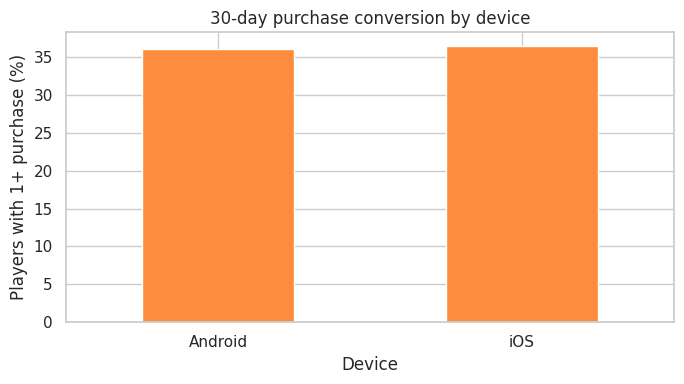

In [14]:
country_summary = summarize_group('Country')
device_summary = summarize_group('Device')
print('Country results:')
display(country_summary.round(2))
print('Device results:')
display(device_summary.round(2))

min_group = 100
country_plot = country_summary[(country_summary['players'] >= min_group) & (country_summary.index.astype(str) != 'Unknown')].sort_values('mean_iap_used_for_summary', ascending=False).head(20).copy()
device_plot = device_summary[(device_summary['players'] >= min_group) & (device_summary.index.astype(str) != 'Unknown')].sort_values('purchase_rate_percent')
country_plot['CountryName'] = country_plot.index.astype(str)
fig = px.scatter(country_plot, x='purchase_rate_percent', y='mean_iap_used_for_summary',
                 size='players', color='mean_purchase_count', hover_name='CountryName',
                 hover_data={'players':':,','purchase_rate_percent':':.1f',
                             'mean_purchase_count':':.2f','mean_iap_used_for_summary':':.2f'},
                 color_continuous_scale='Plasma', size_max=48,
                 title='Country purchase profile (hover for country and sample size)')
fig.update_layout(xaxis_title='Players with 1+ purchase (%)',
                  yaxis_title='Mean IAP value used in summary (USD)')
fig.show()
fig, ax = plt.subplots(figsize=(7,4))
device_plot['purchase_rate_percent'].plot.bar(ax=ax, color='#fd8d3c')
ax.set_title('30-day purchase conversion by device')
ax.set_xlabel('Device'); ax.set_ylabel('Players with 1+ purchase (%)')
ax.tick_params(axis='x', rotation=0); plt.tight_layout(); plt.show()


**Business interpretation:** compare rate, spend per player, and group size together. Differences may reflect class mix or synthetic sampling rather than a real market effect. Treat country and device results as hypotheses for validation, not targeting recommendations.

## 10. Do acquisition channel, payment method, or social features differ?

These are practical campaign questions: which acquisition sources bring players with stronger recorded purchase signals, which payment methods appear among spenders, and whether guild membership or push opt-in is associated with activity/spending. Use within-group rates and median spend, not raw totals alone.

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
AcquisitionChannel,,,,,,,
Referral,30510,11078,3062491.46,107.65,11.88,0.51,36.31
Organic,58735,21320,5773585.51,105.54,11.88,0.51,36.3
Unknown,12375,4401,1186377.41,102.96,11.88,0.5,35.56
Influencer,28292,10250,2675570.14,101.65,11.98,0.5,36.23
Cross-promotion,28080,10108,2637219.79,100.5,12.16,0.51,36.0
Paid Social,56410,20593,5226707.94,99.5,11.88,0.51,36.51
Search Ads,33098,11898,2967942.72,96.3,11.86,0.5,35.95


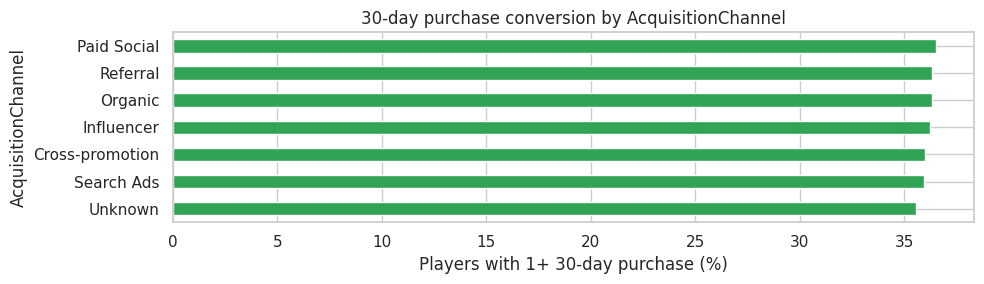

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
PaymentMethod,,,,,,,
Debit Card,34092,12477,4224870.61,127.0,12.58,0.52,36.6
PayPal,31377,11489,3708613.97,121.2,11.97,0.52,36.62
Unknown,21783,8065,1143984.97,109.15,11.86,0.52,37.02
Gift Card,33141,12437,3370252.28,104.2,12.55,0.53,37.53
Carrier Billing,32558,11821,3138599.69,98.93,11.85,0.51,36.31
Credit Card,31839,11282,2912806.36,93.79,10.98,0.48,35.43
Google Pay,33562,11869,2761250.19,84.39,12.16,0.49,35.36
Apple Pay,29148,10208,2269516.9,79.94,11.63,0.47,35.02


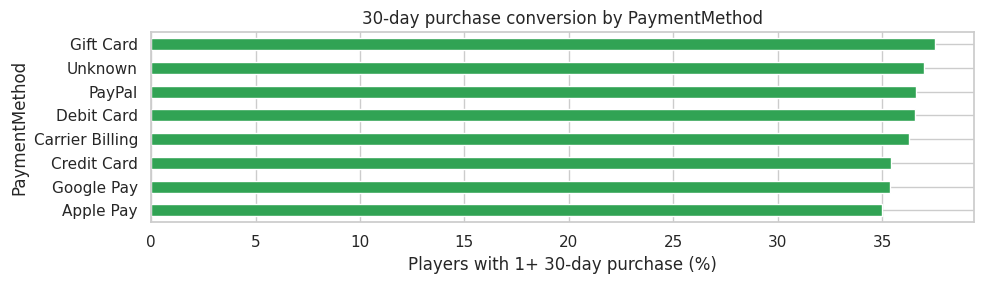

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
GuildMember,,,,,,,
Yes,60801,24141,8368555.84,147.94,12.62,0.58,39.7
No,186699,65507,15161339.13,87.13,11.74,0.48,35.09


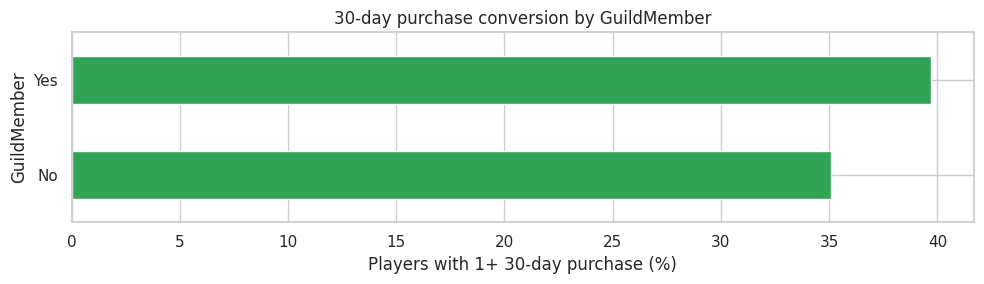

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
PushNotificationsOptIn,,,,,,,
Yes,100651,38411,11558008.12,123.3,12.37,0.55,38.16
No,146849,51237,11971886.85,87.48,11.73,0.48,34.89


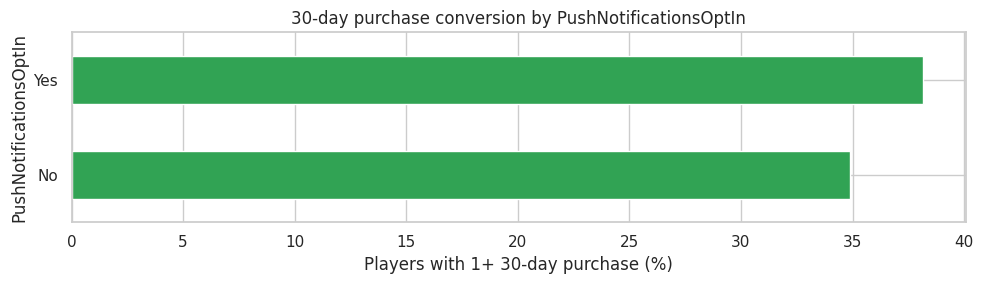

In [15]:
for column in ['AcquisitionChannel','PaymentMethod','GuildMember','PushNotificationsOptIn']:
    summary = summarize_group(column)
    display(summary.round(2))
    eligible = summary[summary['players'] >= min_group].sort_values('purchase_rate_percent')
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(eligible))))
    eligible['purchase_rate_percent'].plot.barh(ax=ax, color='#31a354')
    ax.set_title(f'30-day purchase conversion by {column}')
    ax.set_xlabel('Players with 1+ 30-day purchase (%)')
    ax.set_ylabel(column)
    plt.tight_layout(); plt.show()


**Business interpretation:** these comparisons can identify segments worth testing, but they are observational. Payment method is only observed for players who have payment information, and acquisition-channel differences may reflect targeting or selection effects. Do not infer that a channel or push notification caused purchases.

## 11. Do age and gender relate to spending profiles? (descriptive only)

Compare age distributions by spending tier and segment composition by gender. Gender is included only to describe this dataset; do not use sensitive characteristics to exclude players or make unsupported targeting decisions.

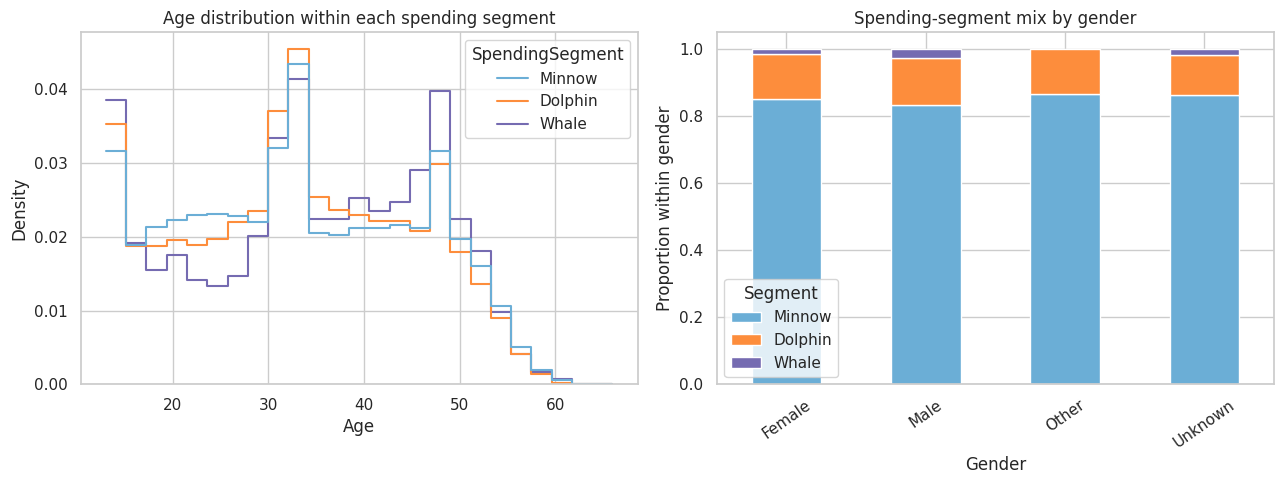

In [16]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.histplot(data=df, x='Age', hue='SpendingSegment', hue_order=segment_order,
             palette=segment_colors, bins=25, stat='density', common_norm=False,
             element='step', fill=False, ax=axes[0])
axes[0].set_title('Age distribution within each spending segment')
axes[0].set_xlabel('Age'); axes[0].set_ylabel('Density')

gender_mix = pd.crosstab(df['Gender'], df['SpendingSegment'], normalize='index').reindex(columns=segment_order, fill_value=0)
gender_mix.plot.bar(stacked=True, ax=axes[1], color=[segment_colors[s] for s in segment_order])
axes[1].set_title('Spending-segment mix by gender')
axes[1].set_xlabel('Gender'); axes[1].set_ylabel('Proportion within gender'); axes[1].tick_params(axis='x',rotation=35)
axes[1].legend(title='Segment')
plt.tight_layout(); plt.show()


## 12. Date-based patterns

Inspect monthly counts for valid install and last-purchase dates. Because the dataset includes missing and simulated dates, state the number of valid dates and interpret trends cautiously. Calendar patterns in this dataset are not proof of seasonal demand.

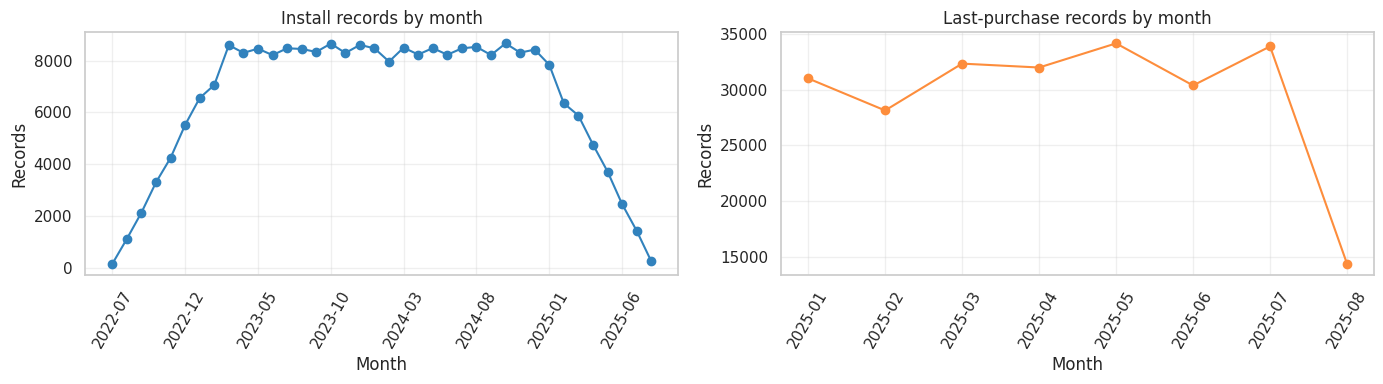

Valid install dates: 247499
Valid last-purchase dates: 236343


In [17]:
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax, column, label, color in [
    (axes[0], 'InstallDate', 'Install records by month', '#3182bd'),
    (axes[1], 'LastPurchaseDate', 'Last-purchase records by month', '#fd8d3c')
]:
    monthly = df[column].dropna().dt.to_period('M').value_counts().sort_index()
    if len(monthly):
        monthly.index = monthly.index.astype(str)
        monthly.plot(ax=ax, marker='o', color=color)
    ax.set_title(label)
    ax.set_xlabel('Month'); ax.set_ylabel('Records')
    ax.tick_params(axis='x',rotation=60)
    ax.grid(True, alpha=.3)
plt.tight_layout(); plt.show()

print('Valid install dates:', int(df['InstallDate'].notna().sum()))
print('Valid last-purchase dates:', int(df['LastPurchaseDate'].notna().sum()))


## 13. Feature engineering: create new player-behavior features

This is the feature-engineering stage: it creates new columns from existing behavior data, rather than only plotting the original columns.

- `AdsPerActiveDay`: ad exposure rate per day played.
- `PurchasesPerActiveDay`: purchase frequency adjusted for days active; only valid as a predictor after the 30-day window.
- `SocialActionsPerActiveDay` and `SessionsPerActiveDay`: activity intensity rates.
- `EngagementActions30d`: combined count of ads watched and social actions.
- `EngagementActionsPerActiveDay`: combined engagement intensity per day active.

Rates make players with different active-day counts more comparable. These features are hypotheses; test whether they add value in modeling.


Raw counts partly depend on how many days a player was active. Create interpretable rates per active day. These features help compare players with different activity levels. Keep purchase-derived rates only if the model's prediction time is after the 30-day observation window.

Created: ['EngagementActions30d', 'AdsPerActiveDay', 'PurchasesPerActiveDay', 'SocialActionsPerActiveDay', 'SessionsPerActiveDay', 'EngagementActionsPerActiveDay']


,EngagementActions30d,AdsPerActiveDay,PurchasesPerActiveDay,SocialActionsPerActiveDay,SessionsPerActiveDay,EngagementActionsPerActiveDay
SpendingSegment,,,,,,
Minnow,9.0,1.25,0.0,0.5,2.0,1.8
Dolphin,7.0,0.625,0.167,0.545,1.714,1.2
Whale,5.0,0.143,0.333,0.571,1.6,0.75


/tmp/ipykernel_798/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_798/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_798/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_798/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_798/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated a

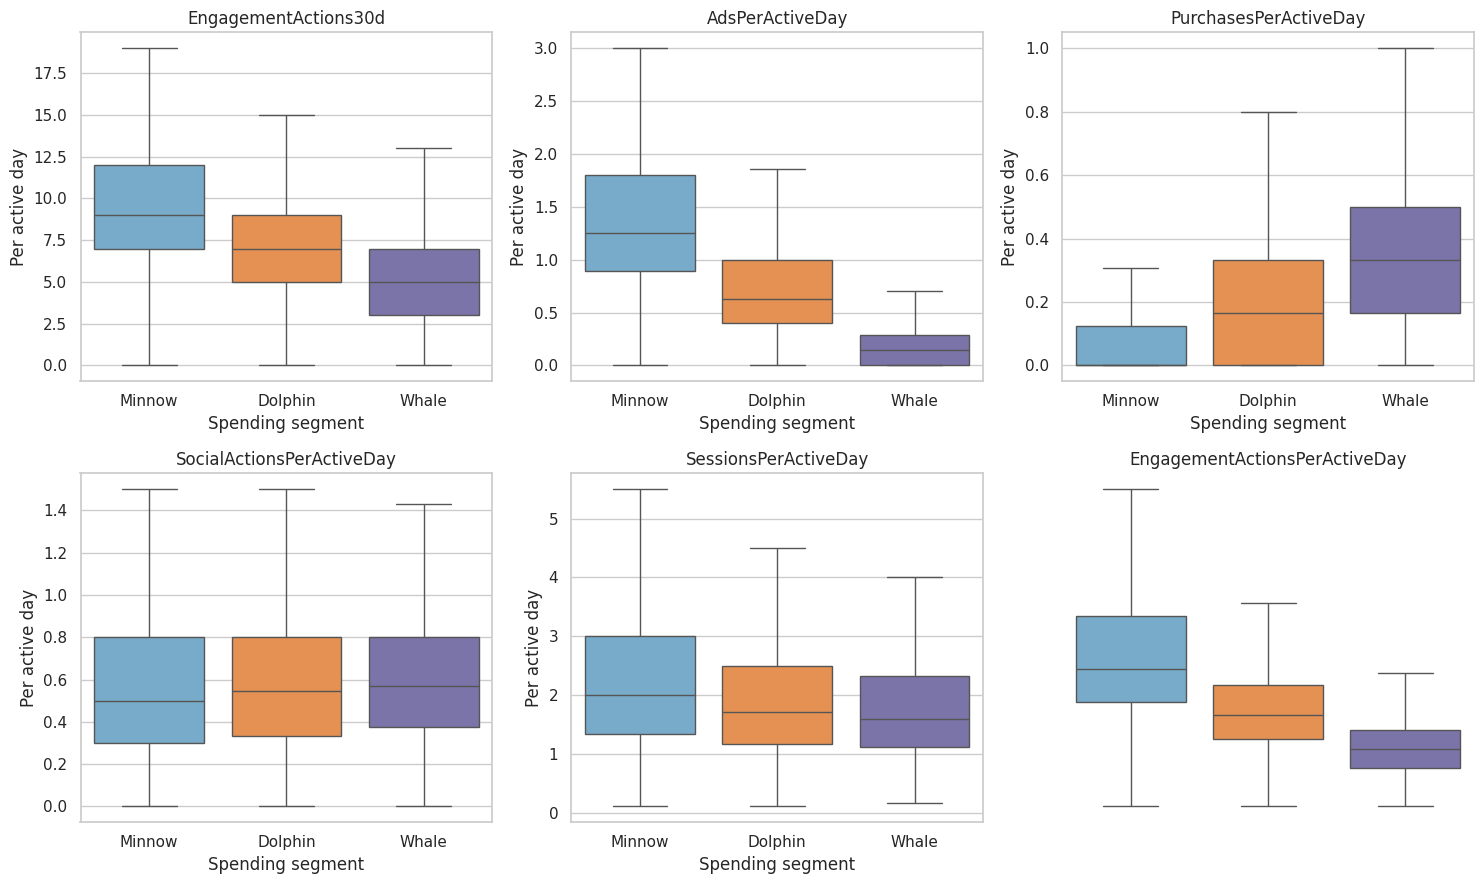

In [18]:
active_days = df['ActiveDays30d'].where(df['ActiveDays30d'] > 0)
df['EngagementActions30d'] = df['AdsWatched30d'] + df['SocialActions30d']
df['AdsPerActiveDay'] = df['AdsWatched30d'] / active_days
df['PurchasesPerActiveDay'] = df['PurchaseCount30d'] / active_days
df['SocialActionsPerActiveDay'] = df['SocialActions30d'] / active_days
df['SessionsPerActiveDay'] = df['SessionCount'] / active_days
df['EngagementActionsPerActiveDay'] = df['EngagementActions30d'] / active_days

new_features = ['EngagementActions30d','AdsPerActiveDay','PurchasesPerActiveDay','SocialActionsPerActiveDay','SessionsPerActiveDay','EngagementActionsPerActiveDay']
print('Created:', new_features)
display(df.groupby('SpendingSegment')[new_features].median().reindex(segment_order).round(3))

fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax, feature in zip(axes.flat, new_features):
    sns.boxplot(data=df, x='SpendingSegment', y=feature, order=segment_order,
                palette=segment_colors, showfliers=False, ax=ax)
    ax.set_title(feature); ax.set_xlabel('Spending segment'); ax.set_ylabel('Per active day')
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()


### Feature decisions

- **Keep as candidate early-behavior features:** `AdsPerActiveDay`, `SocialActionsPerActiveDay`, `SessionsPerActiveDay`, and `EngagementActionsPerActiveDay`, if observed before the prediction cutoff.
- **Use with timing caution:** `PurchasesPerActiveDay` and `PurchaseCount30d` contain purchase behavior. They may be valid for a decision made after day 30, but are leakage for a prediction made before day 30.
- Compare models with and without engineered features using the same train/test split. Features are useful only if they improve appropriate validation metrics and remain available at decision time.

## 14. Correlation and pairwise relationships

Use a Spearman correlation heatmap for numeric variables because several are skewed or count-valued. This helps spot monotonic relationships and redundant measures. Correlation is not causation and may be affected by the data-generation rules.

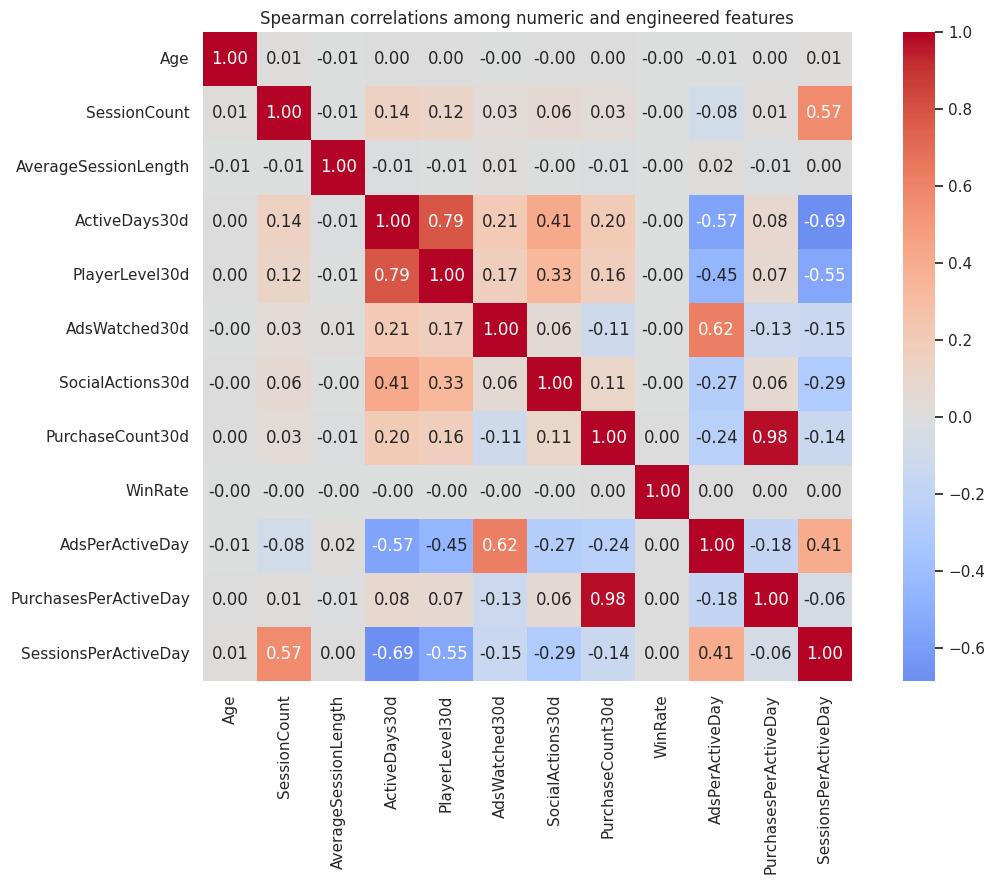

In [19]:
corr_columns = [
    'Age','SessionCount','AverageSessionLength','ActiveDays30d','PlayerLevel30d',
    'AdsWatched30d','SocialActions30d','PurchaseCount30d','WinRate',
    'AdsPerActiveDay','PurchasesPerActiveDay','SessionsPerActiveDay'
]
corr = df[corr_columns].corr(method='spearman')
plt.figure(figsize=(12,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Spearman correlations among numeric and engineered features')
plt.tight_layout(); plt.show()


## 15. Automatically print useful findings from this dataset

Use these values to write your EDA findings. Include group size and describe them as patterns in the simulated training set. A top-ranked group is not automatically meaningfully different from the next group.

In [20]:
eligible_genres = genre_summary[(genre_summary['players'] >= min_group) & (genre_summary.index.astype(str) != 'Unknown')]
eligible_countries = country_summary[(country_summary['players'] >= min_group) & (country_summary.index.astype(str) != 'Unknown')]
eligible_devices = device_summary[(device_summary['players'] >= min_group) & (device_summary.index.astype(str) != 'Unknown')]

print('--- Dataset-specific descriptive findings ---')
if len(eligible_genres):
    g = eligible_genres['mean_iap_used_for_summary'].idxmax()
    print(f'Genre highest in mean IAP value used in the summary: {g}; USD {eligible_genres.loc[g, "mean_iap_used_for_summary"]:.2f}; n={int(eligible_genres.loc[g, "players"]):,}')
    g2 = eligible_genres['purchase_rate_percent'].idxmax()
    print(f'Genre highest in 30-day purchase conversion: {g2}; {eligible_genres.loc[g2, "purchase_rate_percent"]:.2f}%; n={int(eligible_genres.loc[g2, "players"]):,}')
if len(eligible_countries):
    c = eligible_countries['mean_iap_used_for_summary'].idxmax()
    print(f'Country highest in mean IAP value used in the summary: {c}; USD {eligible_countries.loc[c, "mean_iap_used_for_summary"]:.2f}; n={int(eligible_countries.loc[c, "players"]):,}')
    c2 = eligible_countries['purchase_rate_percent'].idxmax()
    print(f'Country highest in 30-day purchase conversion: {c2}; {eligible_countries.loc[c2, "purchase_rate_percent"]:.2f}%; n={int(eligible_countries.loc[c2, "players"]):,}')
if len(eligible_devices):
    d = eligible_devices['purchase_rate_percent'].idxmax()
    print(f'Device highest in 30-day purchase conversion: {d}; {eligible_devices.loc[d, "purchase_rate_percent"]:.2f}%; n={int(eligible_devices.loc[d, "players"]):,}')
print('Spearman ads/purchase-count correlation:', round(df[['AdsWatched30d','PurchaseCount30d']].corr(method='spearman').iloc[0,1],3))
print('All outputs are descriptive and based on synthetic training data.')


--- Dataset-specific descriptive findings ---
Genre highest in mean IAP value used in the summary: Battle Royale; USD 157.14; n=15,431
Genre highest in 30-day purchase conversion: Adventure; 38.98%; n=13,846
Country highest in mean IAP value used in the summary: Afghanistan; USD 221.52; n=7,241
Country highest in 30-day purchase conversion: Afghanistan; 38.72%; n=7,241
Device highest in 30-day purchase conversion: iOS; 36.42%; n=100,524
Spearman ads/purchase-count correlation: -0.105
All outputs are descriptive and based on synthetic training data.


## 16. Modeling readiness — avoid target leakage

If the target is `SpendingSegment`, do not use `InAppPurchaseAmount` as a predictor: it defines or directly reveals spending. Do not use information recorded after the prediction time. `PurchaseCount30d` is only valid if the model is applied after the full 30-day period and that matches the business question. Split before fitting encoders, scalers, or imputers.

In [21]:
target = 'SpendingSegment'
# Strict behavior-based candidates; review against your exact prediction cutoff.
candidate_features = [
    'Age','Gender','Country','Device','GameGenre','SessionCount',
    'AverageSessionLength','ActiveDays30d','PlayerLevel30d','AdsWatched30d',
    'SocialActions30d','WinRate','AdsPerActiveDay',
    'SocialActionsPerActiveDay','SessionsPerActiveDay',
    'EngagementActionsPerActiveDay'
]
X = df[candidate_features].copy()
y = df[target].copy()
print('Candidate feature count:', len(candidate_features))
print('X shape:', X.shape, '| y shape:', y.shape)
print('Excluded direct spending measure: InAppPurchaseAmount')


Candidate feature count: 16
X shape: (247500, 16) | y shape: (247500,)
Excluded direct spending measure: InAppPurchaseAmount


## 17. Save the EDA and feature-engineered dataset

In [22]:
OUTPUT_FILE = 'mobile_game_players_eda_features.csv'
df.to_csv(OUTPUT_FILE, index=False)
print('Saved:', OUTPUT_FILE)


Saved: mobile_game_players_eda_features.csv


## Stage 4 conclusion

In your report, summarize the actual figures printed by the notebook: highest genre/country/device purchase-conversion rates and the largest mean IAP values, ad-view/purchase-count relationship, median first-purchase delay, date coverage, and the engineered activity-rate patterns. Explain why these matter for campaign hypotheses, but state clearly that they are associations in simulated data. A controlled holdout experiment is required to measure incremental revenue, contribution margin after offer cost, and retention.

**Input filename:** `mobile_game_players_cleaned.csv`
**Output filename:** `mobile_game_players_eda_features.csv`
